# Pneumonia detection from chest X-rays — EDA, model selection & tuning

**ML Zoomcamp 2026 · Midterm project**

This notebook contains:

1. Data preparation (catalogue, patient IDs, duplicate check, patient-level split)
2. Exploratory data analysis of the images (class balance, sizes, intensities, mean images, simple global features and how predictive they are)
3. Classical baselines — linear and tree-based models on raw pixels and on CNN embeddings
4. Deep learning — transfer learning with several backbones and head variations (dropout / inner layer), learning-rate, dropout-rate, inner-size tuning and augmentation
5. Final model evaluation on the held-out test set, decision threshold, error analysis and Grad-CAM explanations

The final training logic is exported to `train.py`; shared code (data loading, model, training loop) lives in `common.py`.

In [1]:
import hashlib
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import common
from common import TrainConfig, build_catalogue, metrics, split_by_patient, train_model

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)
FIGS = Path("images"); FIGS.mkdir(exist_ok=True)
DEVICE = common.get_device()
common.seed_everything()
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.15.0 | device: mps


## 1. Data preparation

The dataset is a 624-image subset of the public *Chest X-Ray Images (Pneumonia)* dataset (Kermany et al., 2018, pediatric patients aged 1–5 from Guangzhou Women and Children's Medical Center). It is committed to the repo under `data/chest_xray/{NORMAL,INFECTED}`.

The file names carry useful metadata:

* `person100_bacteria_475.jpeg` → patient `person100`, **bacterial** pneumonia
* `person1_virus_11.jpeg` → patient `person1`, **viral** pneumonia
* `IM-0031-0001.jpeg`, `NORMAL2-IM-0272-0001.jpeg` → healthy patient `IM-0031` / `NORMAL2-IM-0272`

We build a catalogue (one row per image) with the binary target (`label`: 1 = pneumonia), the subtype and the patient ID.

In [2]:
df = build_catalogue()
print(df.shape)
df.head()

(624, 6)


,path,filename,folder,label,subtype,patient
0,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person100_bacteria_475.jpeg,INFECTED,1,bacteria,person100
1,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person100_bacteria_477.jpeg,INFECTED,1,bacteria,person100
2,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person100_bacteria_478.jpeg,INFECTED,1,bacteria,person100
3,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person100_bacteria_479.jpeg,INFECTED,1,bacteria,person100
4,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person100_bacteria_480.jpeg,INFECTED,1,bacteria,person100


In [3]:
print("Missing values per column:\n", df.isna().sum().to_dict())
print("\nImages per folder:\n", df.folder.value_counts().to_dict())
print("\nImages per subtype:\n", df.subtype.value_counts().to_dict())
print("\nUnique patients:", df.patient.nunique())

Missing values per column:
 {'path': 0, 'filename': 0, 'folder': 0, 'label': 0, 'subtype': 0, 'patient': 0}

Images per folder:
 {'INFECTED': 390, 'NORMAL': 234}

Images per subtype:
 {'bacteria': 242, 'normal': 234, 'virus': 148}

Unique patients: 427


**Observations:** 624 images and no missing values. The target is moderately imbalanced: 390 pneumonia images (62.5 %) vs 234 normal. There are 427 unique patients for 624 images, so some patients contribute several X-rays. That matters for the split (section 3).

### Duplicate images

Exact duplicates would inflate scores if they ended up in both train and test, so we hash every file.

In [4]:
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df.path]
dups = df[df.duplicated("md5", keep=False)]
print("exact duplicate files:", len(dups))
dups

exact duplicate files: 12


,path,filename,folder,label,subtype,patient,md5
85,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person128_bacteria_606.jpeg,INFECTED,1,bacteria,person128,62f9117f9c56340e6d34a93de32f320c
86,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person128_bacteria_607.jpeg,INFECTED,1,bacteria,person128,62f9117f9c56340e6d34a93de32f320c
103,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person134_bacteria_643.jpeg,INFECTED,1,bacteria,person134,fe703b7a0f66f29bfb5dc8a003ec3973
104,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person134_bacteria_644.jpeg,INFECTED,1,bacteria,person134,fe703b7a0f66f29bfb5dc8a003ec3973
217,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person1661_virus_2872.jpeg,INFECTED,1,virus,person1661,adf8b53df78fea92adf7ff3e80fb6810
218,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,person1661_virus_2873.jpeg,INFECTED,1,virus,person1661,adf8b53df78fea92adf7ff3e80fb6810
484,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,NORMAL2-IM-0095-0001.jpeg,NORMAL,0,normal,NORMAL2-IM-0095,f9528b244ccd49f3d89ead90ba09c520
485,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,NORMAL2-IM-0096-0001.jpeg,NORMAL,0,normal,NORMAL2-IM-0096,f9528b244ccd49f3d89ead90ba09c520
507,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,NORMAL2-IM-0173-0001-0001.jpeg,NORMAL,0,normal,NORMAL2-IM-0173,f430f3359bdb6b06ebce9008f7d98b7d
508,/Users/shubhamvashishtha/Repos/pneumonia-xray-...,NORMAL2-IM-0173-0001-0002.jpeg,NORMAL,0,normal,NORMAL2-IM-0173,f430f3359bdb6b06ebce9008f7d98b7d


**Observations:** no exact duplicate files.

### Image properties

We open every image once and record size, colour mode, file size and simple intensity statistics. These are used both for EDA and to check whether trivial "shortcut" features already separate the classes.

In [5]:
def image_stats(path):
    im = Image.open(path)
    arr = np.asarray(im.convert("L"), dtype=np.float32) / 255.0
    h, w = arr.shape
    # border vs centre brightness: lungs are dark, a consolidated (infected) lung is whiter
    ch, cw = h // 4, w // 4
    centre = arr[ch:3 * ch, cw:3 * cw]
    return {
        "mode": im.mode, "width": w, "height": h, "aspect": w / h,
        "file_kb": Path(path).stat().st_size / 1024,
        "mean": arr.mean(), "std": arr.std(),
        "p05": np.percentile(arr, 5), "p95": np.percentile(arr, 95),
        "centre_mean": centre.mean(),
    }

stats = pd.DataFrame([image_stats(p) for p in df.path])
df = pd.concat([df, stats], axis=1)
print("colour modes:", df["mode"].value_counts().to_dict())
df.groupby("subtype")[["width", "height", "aspect", "file_kb", "mean", "std", "centre_mean"]].describe().T.round(3)

colour modes: {'L': 624}


subtype            bacteria    normal     virus
width       count   242.000   234.000   148.000
            mean   1076.054  1800.303  1246.730
            std     165.013   365.930   229.336
            min     728.000   984.000   792.000
            25%     952.000  1533.000  1086.000
            50%    1064.000  1762.000  1216.000
            75%    1174.000  2030.250  1380.000
            max    1720.000  2752.000  2000.000
height      count   242.000   234.000   148.000
            mean    724.244  1369.090   832.405
            std     153.576   429.179   229.552
            min     344.000   496.000   440.000
            25%     624.000  1040.000   654.000
            50%     704.000  1317.500   796.000
            75%     812.750  1638.750   978.000
            max    1260.000  2713.000  1456.000
aspect      count   242.000   234.000   148.000
            mean      1.516     1.368     1.546
            std       0.208     0.209     0.236
            min       1.000     0.928     1.093
            25%       1.382     1.213     1.383
            50%       1.495     1.353     1.526
            75%       1.633     1.518     1.688
            max       2.581     2.107     2.382
file_kb     count   242.000   234.000   148.000
            mean     60.111   207.808    94.783
            std      25.082   121.556    47.258
            min      19.205    45.092    28.138
            25%      42.111   125.382    57.109
            50%      54.456   169.411    79.322
            75%      73.112   246.659   122.594
            max     173.657   706.865   256.181
mean        count   242.000   234.000   148.000
            mean      0.457     0.487     0.485
            std       0.066     0.063     0.067
            min       0.265     0.314     0.230
            25%       0.418     0.440     0.440
            50%       0.456     0.487     0.488
            75%       0.500     0.529     0.533
            max       0.612     0.631     0.625
std         count   242.000   234.000   148.000
            mean      0.206     0.236     0.241
            std       0.027     0.026     0.033
            min       0.126     0.130     0.100
            25%       0.188     0.219     0.223
            50%       0.205     0.238     0.241
            75%       0.220     0.253     0.262
            max       0.285     0.305     0.309
centre_mean count   242.000   234.000   148.000
            mean      0.570     0.555     0.592
            std       0.071     0.060     0.068
            min       0.349     0.385     0.233
            25%       0.532     0.516     0.566
            50%       0.577     0.555     0.600
            75%       0.623     0.593     0.631
            max       0.702     0.717     0.727

## 2. Exploratory data analysis

### 2.1 Target variable

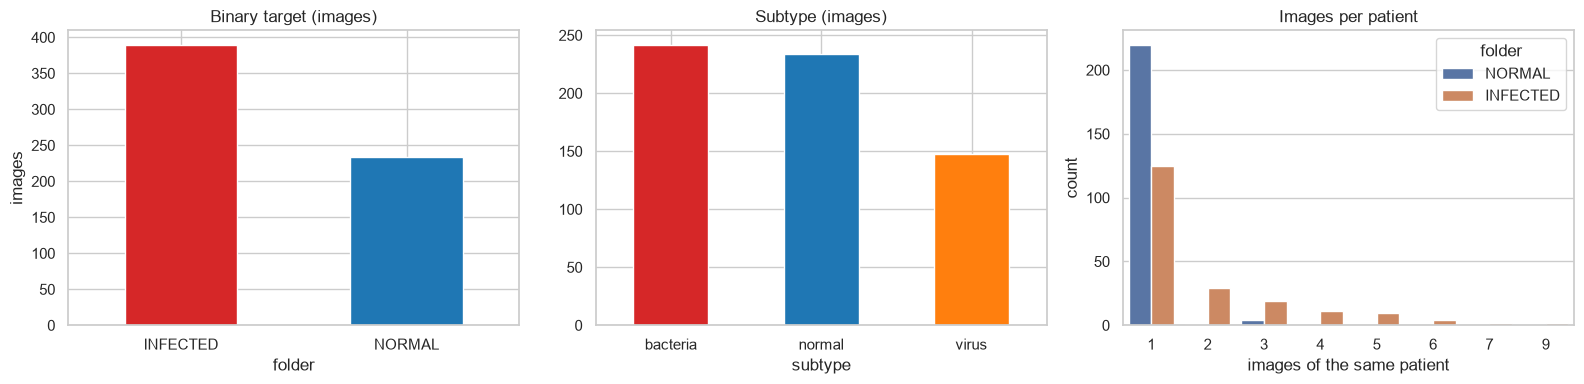

Pneumonia share: 62.5%
              mean  max
folder                 
INFECTED  1.930693    9
NORMAL    1.040000    3


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.folder.value_counts().plot.bar(ax=axes[0], color=["tab:red", "tab:blue"])
axes[0].set_title("Binary target (images)"); axes[0].set_ylabel("images")
df.subtype.value_counts().plot.bar(ax=axes[1], color=["tab:red", "tab:blue", "tab:orange"])
axes[1].set_title("Subtype (images)")
per_patient = df.groupby(["patient", "folder"]).size().rename("n").reset_index()
sns.countplot(data=per_patient, x="n", hue="folder", ax=axes[2])
axes[2].set_title("Images per patient"); axes[2].set_xlabel("images of the same patient")
for ax in axes[:2]: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIGS / "eda_target.png", dpi=110); plt.show()

print(f"Pneumonia share: {df.label.mean():.1%}")
print(per_patient.groupby("folder").n.agg(["mean", "max"]))

**Observations:** 38 % of pneumonia patients have more than one image (up to 9), while 98 % of normal patients have exactly one. Splitting by image would leak patient identity into the test set. We handle the imbalance with a class-weighted loss rather than resampling.

### 2.2 Sample images

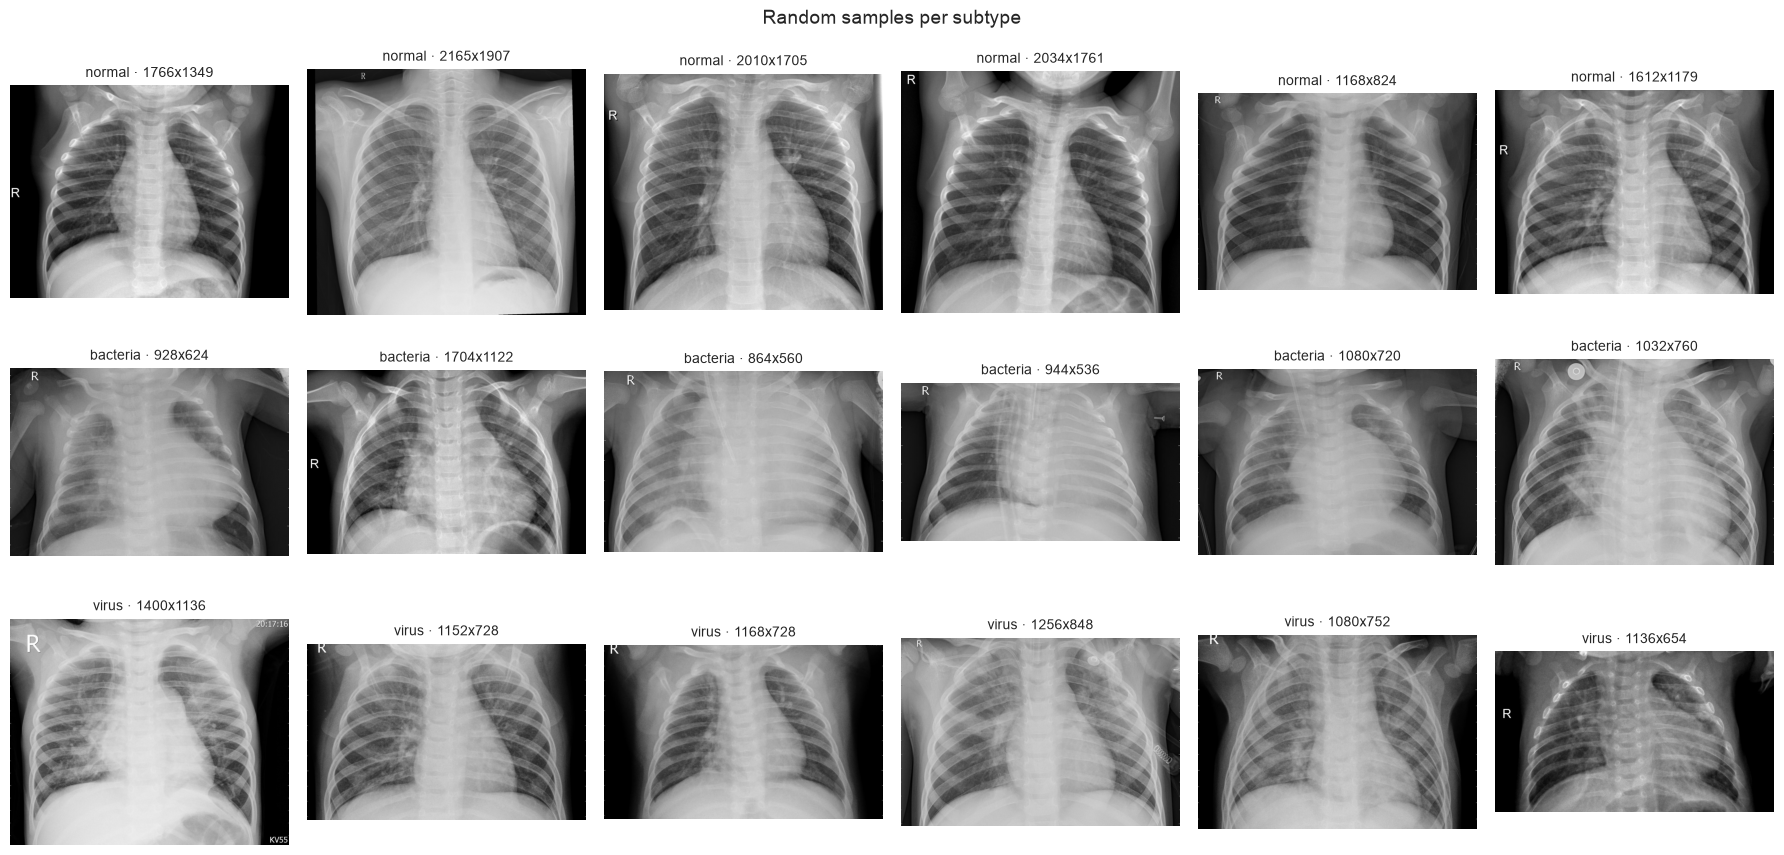

In [7]:
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for row, st in enumerate(["normal", "bacteria", "virus"]):
    sample = df[df.subtype == st].sample(6, random_state=1)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        ax.imshow(Image.open(r.path), cmap="gray")
        ax.set_title(f"{st} · {r.width}x{r.height}", fontsize=10)
        ax.axis("off")
plt.suptitle("Random samples per subtype", fontsize=14)
plt.tight_layout(); plt.savefig(FIGS / "eda_samples.png", dpi=110); plt.show()

### 2.3 Image sizes and aspect ratios

The images vary a lot in resolution, so they must be resized to a fixed input size. We also check whether size itself differs between classes — if it does, a model could learn the *scanner/acquisition* instead of the disease.

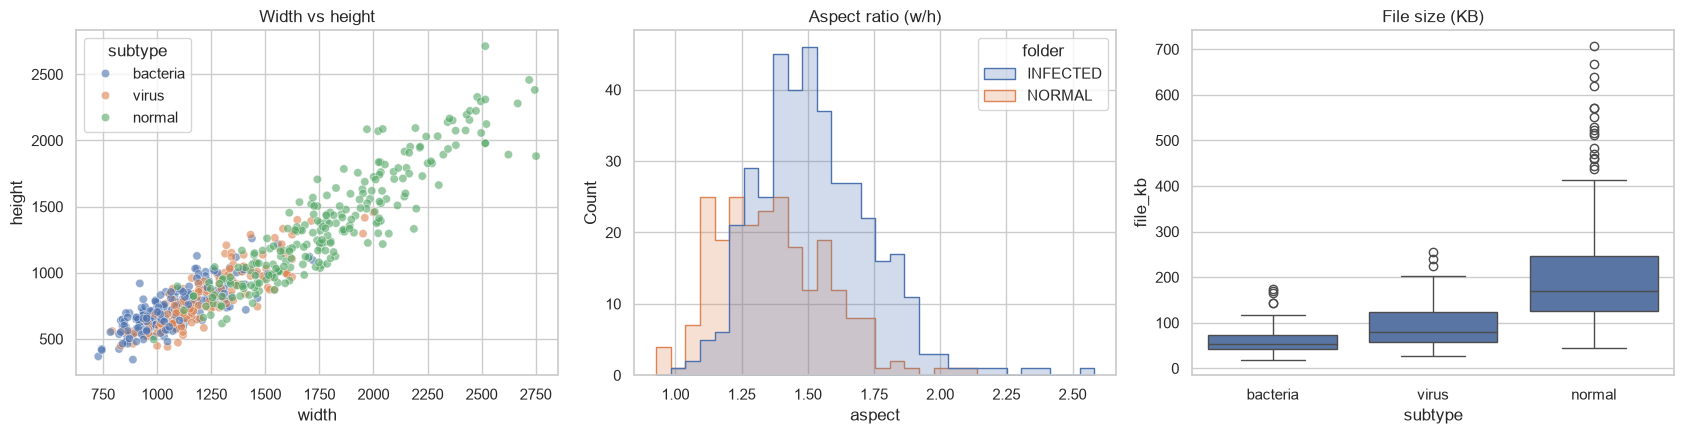

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="width", y="height", hue="subtype", alpha=0.6, ax=axes[0])
axes[0].set_title("Width vs height")
sns.histplot(data=df, x="aspect", hue="folder", bins=30, element="step", ax=axes[1])
axes[1].set_title("Aspect ratio (w/h)")
sns.boxplot(data=df, x="subtype", y="file_kb", ax=axes[2])
axes[2].set_title("File size (KB)")
plt.tight_layout(); plt.savefig(FIGS / "eda_sizes.png", dpi=110); plt.show()

**Observations:** resolution varies from about 400 to 2900 px, and **normal images are systematically larger** (and larger on disk) than pneumonia images. Pneumonia images also tend to be wider relative to their height. These are properties of how the images were acquired or exported, not of the disease, so the model must not be able to rely on them. Every image is therefore resized to a fixed 224×224 input.

### 2.4 Pixel intensities

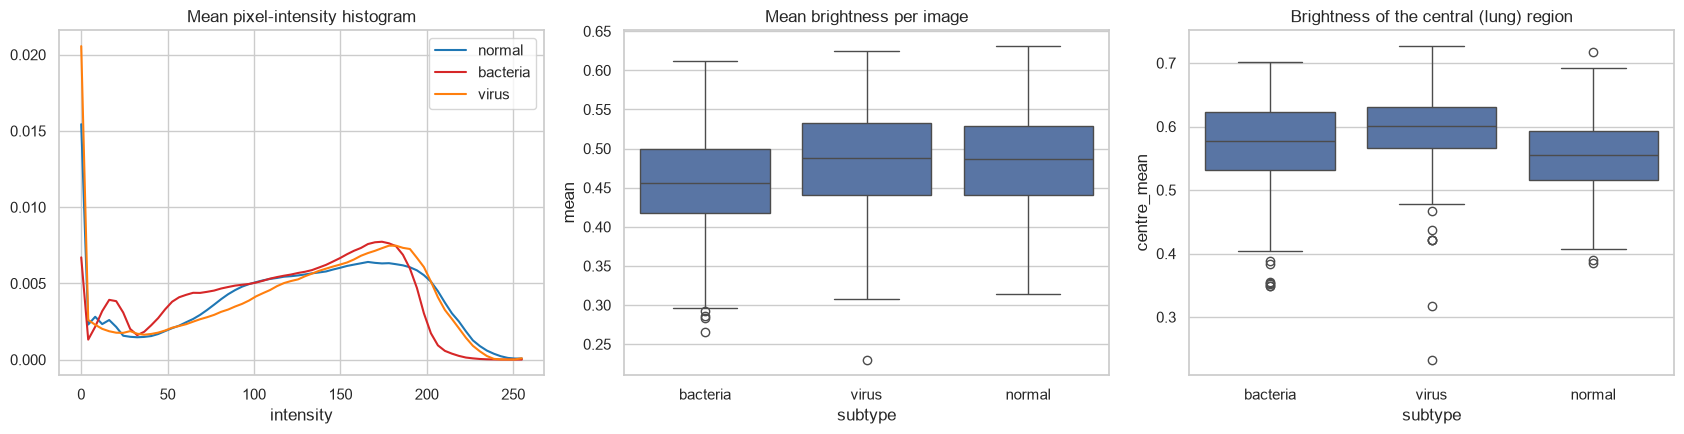

In [9]:
def intensity_hist(paths, bins=64):
    h = np.zeros(bins)
    for p in paths:
        arr = np.asarray(Image.open(p).convert("L").resize((256, 256)))
        h += np.histogram(arr, bins=bins, range=(0, 255), density=True)[0]
    return h / len(paths)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.linspace(0, 255, 64)
for st, c in [("normal", "tab:blue"), ("bacteria", "tab:red"), ("virus", "tab:orange")]:
    axes[0].plot(x, intensity_hist(df[df.subtype == st].path), label=st, color=c)
axes[0].set_title("Mean pixel-intensity histogram"); axes[0].legend(); axes[0].set_xlabel("intensity")
sns.boxplot(data=df, x="subtype", y="mean", ax=axes[1]); axes[1].set_title("Mean brightness per image")
sns.boxplot(data=df, x="subtype", y="centre_mean", ax=axes[2]); axes[2].set_title("Brightness of the central (lung) region")
plt.tight_layout(); plt.savefig(FIGS / "eda_intensity.png", dpi=110); plt.show()

**Observations:** the intensity histograms overlap heavily. Pneumonia images have slightly more mid-to-high intensities, and their central lung region is brighter, which is consistent with lung opacities. Global brightness alone separates the classes poorly.

### 2.5 Average image per class

Averaging all resized images of a class shows where the classes differ on average. The difference map (pneumonia − normal) highlights regions that are brighter in infected lungs.

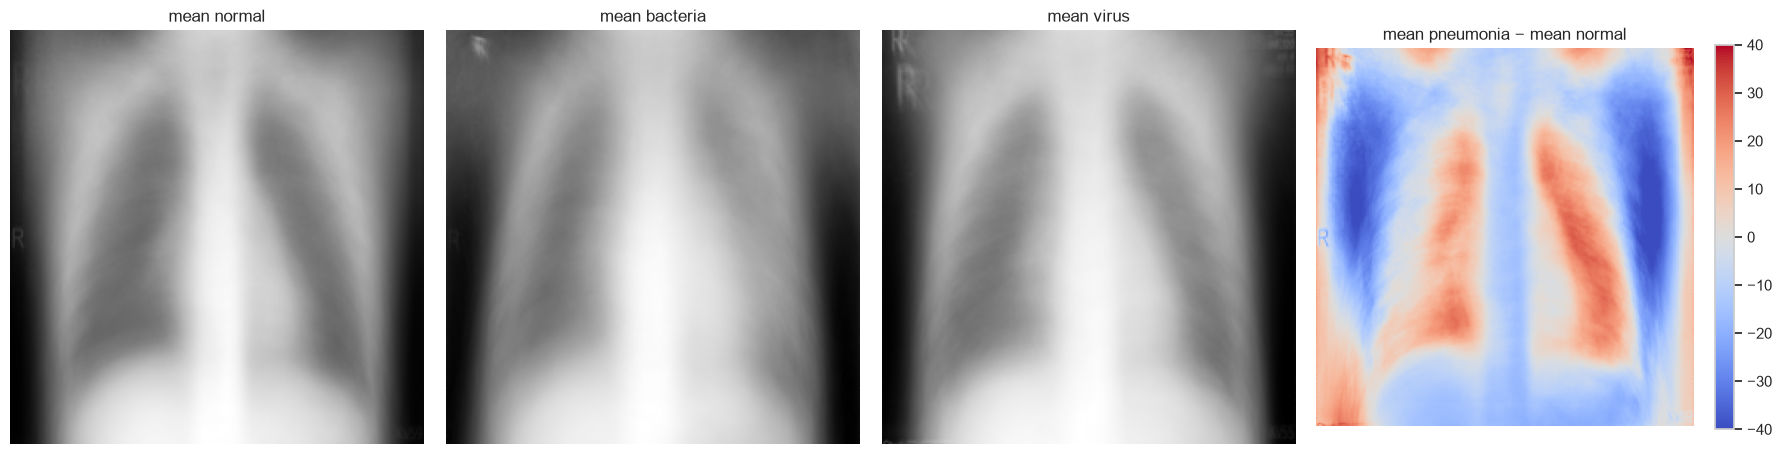

In [10]:
def mean_image(paths, size=(256, 256)):
    return np.mean([np.asarray(Image.open(p).convert("L").resize(size), dtype=np.float32) for p in paths], axis=0)

means = {st: mean_image(df[df.subtype == st].path) for st in ["normal", "bacteria", "virus"]}
diff = mean_image(df[df.label == 1].path) - means["normal"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (st, m) in zip(axes, means.items()):
    ax.imshow(m, cmap="gray"); ax.set_title(f"mean {st}"); ax.axis("off")
im = axes[3].imshow(diff, cmap="coolwarm", vmin=-40, vmax=40)
axes[3].set_title("mean pneumonia − mean normal"); axes[3].axis("off")
plt.colorbar(im, ax=axes[3], fraction=0.046)
plt.tight_layout(); plt.savefig(FIGS / "eda_mean_images.png", dpi=110); plt.show()

**Observations:** the difference map is **red (brighter in pneumonia) over both lung fields**, which matches the opacification caused by infection. This is the signal we want the model to learn. The blue bands at the lateral edges show that normal images include more soft tissue at the sides: another framing difference between the two sources.

### 2.6 Feature importance of simple global features

For images there are no tabular features, but we can still measure how much information simple, hand-crafted image features carry. We compute the univariate ROC-AUC of each feature for the binary target (0.5 = useless, 1.0 / 0.0 = perfectly separating) and the impurity-based importance from a random forest trained on them.

This is also a **leakage check**: features like resolution or file size should not be strongly predictive of a disease — if they are, the model may learn acquisition artefacts.

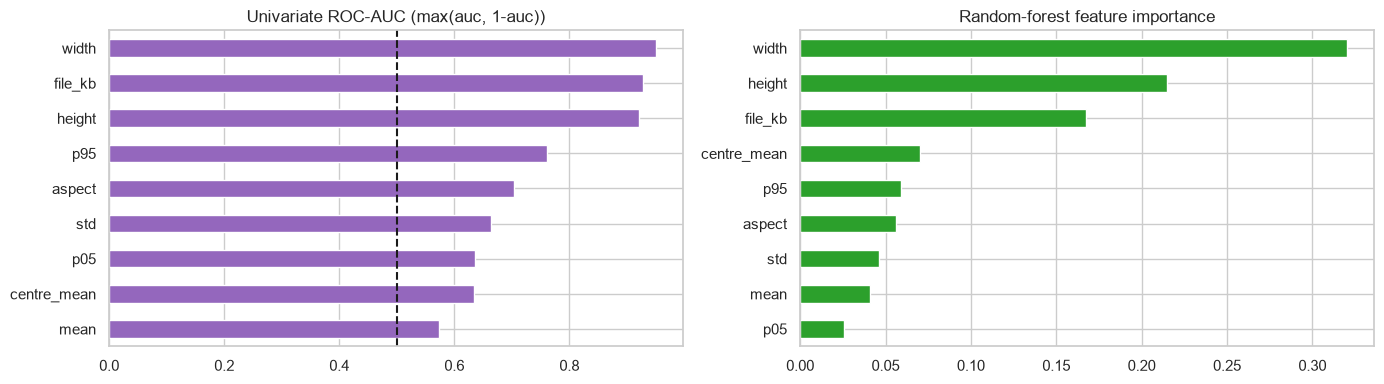

,univariate_auc,rf_importance
aspect,0.704,0.056
centre_mean,0.633,0.070
file_kb,0.927,0.167
height,0.920,0.215
mean,0.573,0.041
p05,0.637,0.026
p95,0.760,0.059
std,0.663,0.046
width,0.950,0.320


In [11]:
feat_cols = ["width", "height", "aspect", "file_kb", "mean", "std", "p05", "p95", "centre_mean"]
auc = {c: roc_auc_score(df.label, df[c]) for c in feat_cols}
auc = pd.Series(auc).apply(lambda a: max(a, 1 - a)).sort_values(ascending=False)

rf_feat = RandomForestClassifier(n_estimators=300, random_state=42).fit(df[feat_cols], df.label)
imp = pd.Series(rf_feat.feature_importances_, index=feat_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
auc.plot.barh(ax=axes[0], color="tab:purple"); axes[0].axvline(0.5, ls="--", c="k")
axes[0].set_title("Univariate ROC-AUC (max(auc, 1-auc))"); axes[0].invert_yaxis()
imp.plot.barh(ax=axes[1], color="tab:green"); axes[1].set_title("Random-forest feature importance"); axes[1].invert_yaxis()
plt.tight_layout(); plt.savefig(FIGS / "eda_feature_importance.png", dpi=110); plt.show()
pd.DataFrame({"univariate_auc": auc, "rf_importance": imp}).round(3)

**Observations (important):** **image width alone has a univariate ROC-AUC of ≈ 0.95**, and size-related features dominate the random-forest importance. Intensity features (`p95`, `centre_mean`), which reflect actual lung content, are informative but weaker. This is a known bias of this dataset: healthy and sick images were acquired or exported differently.

Consequences for modelling:
1. All images are resized to the same square size, so absolute resolution and file size are not available to the CNN.
2. Aspect ratio still has some signal (AUC ≈ 0.70) and is partly encoded in the stretching caused by resizing. We acknowledge this as a limitation, and check with Grad-CAM (section 6) that the model looks at the lungs.

## 3. Train / validation / test split (by patient)

Several patients have more than one X-ray. A random image-level split would put images of the same patient in train and test, which leaks information. We therefore use `StratifiedGroupKFold` (groups = patient, stratified on subtype) to produce a **60 / 20 / 20** split. The split is deterministic (seed 42) and identical in `train.py`.

In [12]:
df = split_by_patient(df)
print(pd.crosstab(df.split, df.subtype, margins=True))
overlap = set(df[df.split == "train"].patient) & set(df[df.split == "test"].patient)
print("patients shared between train and test:", len(overlap))
df[["filename", "label", "subtype", "patient", "split"]].to_csv(REPORTS / "split.csv", index=False)
train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])

subtype  bacteria  normal  virus  All
split                                
test           49      46     30  125
train         145     141     89  375
val            48      47     29  124
All           242     234    148  624
patients shared between train and test: 0


## 4. Baselines: linear and tree-based models

Before deep learning we establish baselines with classical models, using two kinds of input features:

* **Raw pixels** — each image downsampled to 32×32 grayscale (1024 features)
* **CNN embeddings** — the 960-d output of an ImageNet-pre-trained MobileNetV3 (frozen, no fine-tuning)

For each, we tune a **logistic regression** (regularisation `C`) and a **random forest** (`n_estimators`, `max_depth`, `min_samples_leaf`) on the validation set.

In [13]:
def pixels(paths, size=32):
    return np.stack([np.asarray(Image.open(p).convert("L").resize((size, size)), dtype=np.float32).ravel() / 255 for p in paths])

@torch.no_grad()
def embeddings(frame):
    net = common.XrayNet("mobilenet_v3_large").to(DEVICE).eval()
    loader = common.make_loader(frame, train=False)
    return np.concatenate([net.features(x.to(DEVICE)).cpu().numpy() for x, _ in loader])

X = {
    "pixels": {s: pixels(d.path) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]},
    "embeddings": {s: embeddings(d) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]},
}
y = {"train": train_df.label.values, "val": val_df.label.values, "test": test_df.label.values}
print({k: v["train"].shape for k, v in X.items()})

{'pixels': (375, 1024), 'embeddings': (375, 960)}


In [14]:
rows = []
for feats in X:
    for C in [0.001, 0.01, 0.1, 1, 10]:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
        m.fit(X[feats]["train"], y["train"])
        p = m.predict_proba(X[feats]["val"])[:, 1]
        rows.append({"features": feats, "model": "logistic_regression", "params": f"C={C}", **metrics(y["val"], p)})
    for n in [100, 300]:
        for depth in [None, 10]:
            for leaf in [1, 5]:
                m = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_leaf=leaf, random_state=42, n_jobs=-1)
                m.fit(X[feats]["train"], y["train"])
                p = m.predict_proba(X[feats]["val"])[:, 1]
                rows.append({"features": feats, "model": "random_forest",
                             "params": f"n={n},depth={depth},leaf={leaf}", **metrics(y["val"], p)})

baselines = pd.DataFrame(rows).round(4)
baselines.to_csv(REPORTS / "baselines.csv", index=False)
best_baselines = baselines.sort_values("roc_auc", ascending=False).groupby(["features", "model"]).head(1)
best_baselines.sort_values("roc_auc", ascending=False)

,features,model,params,roc_auc,accuracy,precision,recall,f1
21,embeddings,random_forest,"n=100,depth=10,leaf=5",0.9784,0.8952,0.8721,0.9740,0.9202
14,embeddings,logistic_regression,C=0.01,0.9773,0.9113,0.9125,0.9481,0.9299
3,pixels,logistic_regression,C=1,0.9511,0.8790,0.8875,0.9221,0.9045
10,pixels,random_forest,"n=300,depth=None,leaf=5",0.9428,0.8306,0.8256,0.9221,0.8712


**Observations:** even a linear model on raw 32×32 pixels reaches about 0.95 validation ROC-AUC. Features from an ImageNet CNN are much better (about 0.98) for both the linear and the tree-based model, so pre-trained visual features transfer well to X-rays. These are the numbers the fine-tuned CNN has to beat.

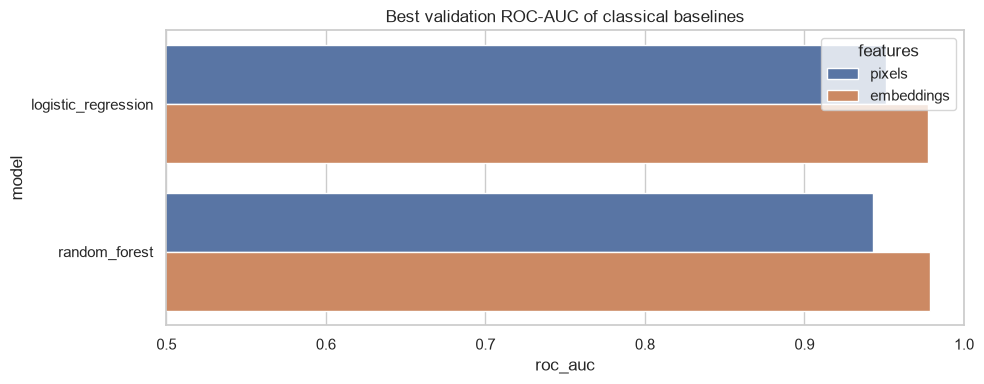

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=baselines, x="roc_auc", y="model", hue="features", estimator="max", errorbar=None, ax=ax)
ax.set_xlim(0.5, 1.0); ax.set_title("Best validation ROC-AUC of classical baselines")
plt.tight_layout(); plt.savefig(FIGS / "baselines.png", dpi=110); plt.show()

## 5. Deep learning: transfer learning with PyTorch

Architecture (`common.XrayNet`): an ImageNet-pre-trained backbone → global average pooling → optional inner dense layer (+ReLU) → optional dropout → one output logit. Training uses AdamW, a cosine learning-rate schedule, class-weighted binary cross-entropy, and **early stopping on validation ROC-AUC** (the best epoch's weights are kept).

The search is done in stages (each stage keeps the best setting found so far), to keep compute reasonable on a laptop:

| Stage | What varies |
|---|---|
| 1 | backbone (MobileNetV3-Large, EfficientNet-B0, ResNet-18) and frozen vs fine-tuned |
| 2 | learning rate |
| 3 | head: inner layer size × dropout rate (with/without each) |
| 4 | data augmentation on/off |

Model selection metric: **validation ROC-AUC** (threshold-independent; the threshold is chosen afterwards).

In [16]:
experiments = []

def run(stage, **kwargs):
    cfg = TrainConfig(epochs=10, patience=3, **kwargs)
    print(f"[{stage}]", {k: v for k, v in kwargs.items()})
    model, res = train_model(cfg, train_df, val_df, device=DEVICE, verbose=False)
    del model; common.free_memory()  # keep RAM flat on small (8 GB) machines
    row = {"stage": stage, **res.summary()}
    experiments.append(row)
    print(f"   -> val_auc={row['val_auc']:.4f} (best epoch {row['best_epoch']}, {row['seconds']:.0f}s)")
    return res

def best(stage):
    return max((e for e in experiments if e["stage"] == stage), key=lambda e: e["val_auc"])

### Stage 1 — backbone and fine-tuning

In [17]:
histories = {}
for bb in ["mobilenet_v3_large", "efficientnet_b0", "resnet18"]:
    histories[f"{bb} (fine-tuned)"] = run("1_backbone", backbone=bb).history
histories["mobilenet_v3_large (frozen)"] = run("1_backbone", backbone="mobilenet_v3_large", freeze_backbone=True, learning_rate=1e-3).history

s1 = best("1_backbone")
BACKBONE, FREEZE = s1["backbone"], s1["freeze_backbone"]
print("best:", BACKBONE, "frozen" if FREEZE else "fine-tuned")

[1_backbone] {'backbone': 'mobilenet_v3_large'}


   -> val_auc=0.9964 (best epoch 6, 43s)
[1_backbone] {'backbone': 'efficientnet_b0'}


   -> val_auc=0.9876 (best epoch 4, 64s)
[1_backbone] {'backbone': 'resnet18'}


   -> val_auc=0.9851 (best epoch 4, 48s)
[1_backbone] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': True, 'learning_rate': 0.001}


   -> val_auc=0.9138 (best epoch 7, 21s)
best: mobilenet_v3_large fine-tuned


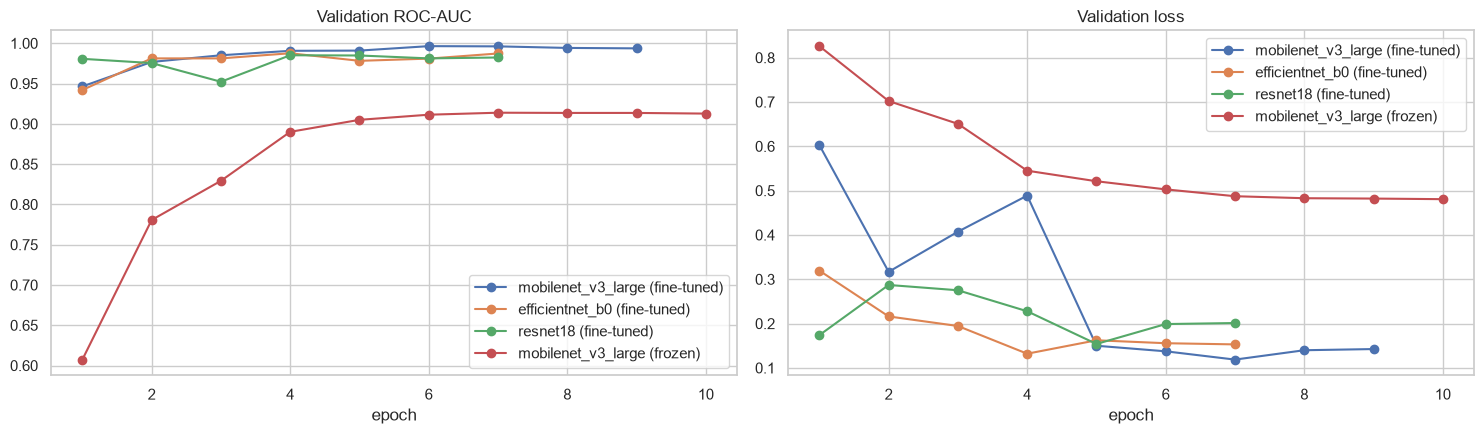

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, h in histories.items():
    h = pd.DataFrame(h)
    axes[0].plot(h.epoch, h.val_auc, marker="o", label=name)
    axes[1].plot(h.epoch, h.val_loss, marker="o", label=name)
axes[0].set_title("Validation ROC-AUC"); axes[1].set_title("Validation loss")
for ax in axes: ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "stage1_backbones.png", dpi=110); plt.show()

**Observations:** fine-tuning the whole network clearly beats training only the head on a frozen backbone (0.996 vs 0.914): X-rays look very different from ImageNet photos, so the features need to adapt. MobileNetV3-Large is the best fine-tuned backbone and is also the smallest and fastest, which is ideal for a CPU web service. Validation loss is noisy in the first epochs, which is why we select by ROC-AUC with early stopping.

### Stage 2 — learning rate

[2_learning_rate] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0001}


   -> val_auc=0.9831 (best epoch 8, 57s)
[2_learning_rate] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003}


   -> val_auc=0.9964 (best epoch 6, 50s)
[2_learning_rate] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.001}


   -> val_auc=0.9889 (best epoch 6, 50s)
best learning rate: 0.0003


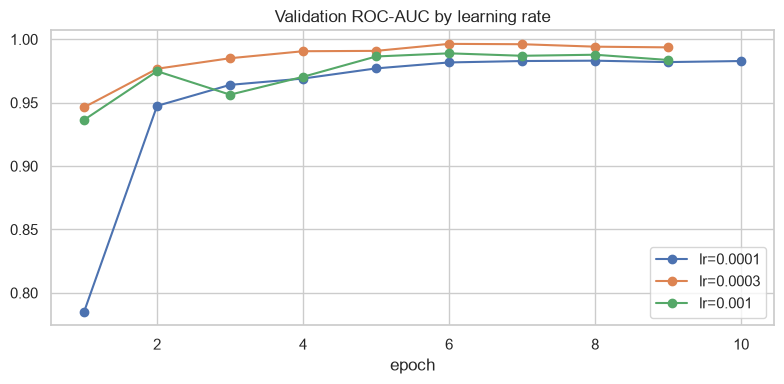

In [19]:
lr_hist = {}
for lr in [1e-4, 3e-4, 1e-3]:
    lr_hist[lr] = run("2_learning_rate", backbone=BACKBONE, freeze_backbone=FREEZE, learning_rate=lr).history
LR = best("2_learning_rate")["learning_rate"]
print("best learning rate:", LR)

fig, ax = plt.subplots(figsize=(8, 4))
for lr, h in lr_hist.items():
    h = pd.DataFrame(h); ax.plot(h.epoch, h.val_auc, marker="o", label=f"lr={lr}")
ax.set_title("Validation ROC-AUC by learning rate"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "stage2_lr.png", dpi=110); plt.show()

**Observations:** 1e-4 learns too slowly within 10 epochs, and 1e-3 is less stable. **3e-4** gives the best validation ROC-AUC.

### Stage 3 — inner layer size × dropout rate

[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 0, 'dropout': 0.0}


   -> val_auc=0.9964 (best epoch 6, 49s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 0, 'dropout': 0.2}


   -> val_auc=0.9895 (best epoch 7, 55s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 0, 'dropout': 0.5}


   -> val_auc=0.9939 (best epoch 6, 50s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 64, 'dropout': 0.0}


   -> val_auc=0.9784 (best epoch 2, 29s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 64, 'dropout': 0.2}


   -> val_auc=0.9608 (best epoch 1, 26s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 64, 'dropout': 0.5}


   -> val_auc=0.9972 (best epoch 7, 55s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 256, 'dropout': 0.0}


   -> val_auc=0.9845 (best epoch 7, 52s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 256, 'dropout': 0.2}


   -> val_auc=0.9793 (best epoch 2, 28s)
[3_head] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 256, 'dropout': 0.5}


   -> val_auc=0.9834 (best epoch 4, 37s)


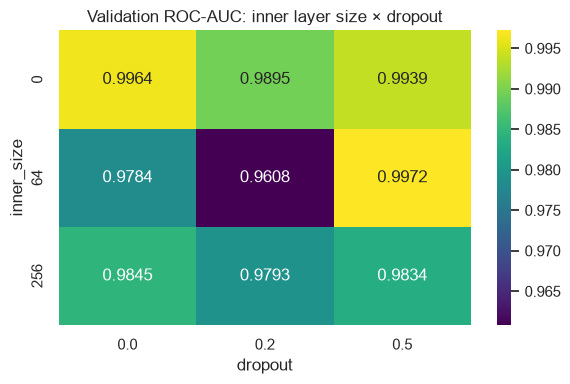

best head: inner_size = 64 dropout = 0.5


In [20]:
for inner in [0, 64, 256]:
    for drop in [0.0, 0.2, 0.5]:
        run("3_head", backbone=BACKBONE, freeze_backbone=FREEZE, learning_rate=LR, inner_size=inner, dropout=drop)

s3 = pd.DataFrame([e for e in experiments if e["stage"] == "3_head"])
pivot = s3.pivot(index="inner_size", columns="dropout", values="val_auc")
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis", ax=ax)
ax.set_title("Validation ROC-AUC: inner layer size × dropout")
plt.tight_layout(); plt.savefig(FIGS / "stage3_head.png", dpi=110); plt.show()

INNER, DROPOUT = best("3_head")["inner_size"], best("3_head")["dropout"]
print("best head: inner_size =", INNER, "dropout =", DROPOUT)

**Observations:** an inner layer without dropout overfits quickly (best epoch 1–2). A **64-unit inner layer with 0.5 dropout** is best (0.997), essentially tied with no inner layer (0.996). With 124 validation images, differences below about 0.01 are within noise. We still take the best configuration, as planned.

### Stage 4 — data augmentation

In [21]:
run("4_augmentation", backbone=BACKBONE, freeze_backbone=FREEZE, learning_rate=LR, inner_size=INNER, dropout=DROPOUT, augment=False)
aug_on = best("3_head")
aug_off = best("4_augmentation")
AUGMENT = aug_on["val_auc"] >= aug_off["val_auc"]
print(f"augmentation on: {aug_on['val_auc']:.4f} | off: {aug_off['val_auc']:.4f} -> use augmentation = {AUGMENT}")

[4_augmentation] {'backbone': 'mobilenet_v3_large', 'freeze_backbone': False, 'learning_rate': 0.0003, 'inner_size': 64, 'dropout': 0.5, 'augment': False}


   -> val_auc=0.9831 (best epoch 1, 22s)
augmentation on: 0.9972 | off: 0.9831 -> use augmentation = True


**Observations:** without augmentation the model overfits after one epoch and validation ROC-AUC drops to 0.983. Augmentation is kept.

In [22]:
exp = pd.DataFrame(experiments)
exp.to_csv(REPORTS / "experiments.csv", index=False)
cols = ["stage", "backbone", "freeze_backbone", "learning_rate", "inner_size", "dropout", "augment", "best_epoch", "val_auc", "seconds"]
exp[cols].sort_values("val_auc", ascending=False)

,stage,backbone,freeze_backbone,learning_rate,inner_size,dropout,augment,best_epoch,val_auc,seconds
12,3_head,mobilenet_v3_large,False,0.0003,64,0.5,True,7,0.9972,55.2
0,1_backbone,mobilenet_v3_large,False,0.0003,0,0.0,True,6,0.9964,43.1
5,2_learning_rate,mobilenet_v3_large,False,0.0003,0,0.0,True,6,0.9964,50.0
7,3_head,mobilenet_v3_large,False,0.0003,0,0.0,True,6,0.9964,49.0
9,3_head,mobilenet_v3_large,False,0.0003,0,0.5,True,6,0.9939,50.4
8,3_head,mobilenet_v3_large,False,0.0003,0,0.2,True,7,0.9895,54.9
6,2_learning_rate,mobilenet_v3_large,False,0.0010,0,0.0,True,6,0.9889,49.5
1,1_backbone,efficientnet_b0,False,0.0003,0,0.0,True,4,0.9876,63.7
2,1_backbone,resnet18,False,0.0003,0,0.0,True,4,0.9851,48.5
13,3_head,mobilenet_v3_large,False,0.0003,256,0.0,True,7,0.9845,51.5


**Selected configuration:** MobileNetV3-Large, fine-tuned, lr 3e-4, inner layer 64, dropout 0.5, augmentation on.

## 6. Final model

We retrain the selected configuration (same seed, so this reproduces the experiment) and evaluate it **once** on the untouched test set. This is exactly what `train.py` does.

In [23]:
FINAL = TrainConfig(backbone=BACKBONE, freeze_backbone=FREEZE, learning_rate=LR, inner_size=INNER,
                    dropout=DROPOUT, augment=AUGMENT, epochs=10, patience=3)
print(FINAL)
model, res = train_model(FINAL, train_df, val_df, device=DEVICE)
json.dump(res.summary(), open(REPORTS / "final_config.json", "w"), indent=2)

TrainConfig(backbone='mobilenet_v3_large', freeze_backbone=False, learning_rate=0.0003, inner_size=64, dropout=0.5, augment=True, epochs=10, batch_size=16, weight_decay=0.0001, patience=3, seed=42)


  epoch  1 train_loss=0.4237 val_loss=0.4698 val_auc=0.9704 val_acc=0.7339


  epoch  2 train_loss=0.1937 val_loss=2.2005 val_auc=0.9323 val_acc=0.6210


  epoch  3 train_loss=0.1253 val_loss=0.8784 val_auc=0.9818 val_acc=0.7339


  epoch  4 train_loss=0.0785 val_loss=1.4226 val_auc=0.9856 val_acc=0.7016


  epoch  5 train_loss=0.1325 val_loss=0.1831 val_auc=0.9840 val_acc=0.9435


  epoch  6 train_loss=0.1203 val_loss=0.1332 val_auc=0.9925 val_acc=0.9597


  epoch  7 train_loss=0.0819 val_loss=0.1381 val_auc=0.9972 val_acc=0.9435


  epoch  8 train_loss=0.0569 val_loss=0.1480 val_auc=0.9959 val_acc=0.9435


  epoch  9 train_loss=0.0431 val_loss=0.1397 val_auc=0.9953 val_acc=0.9516


  epoch 10 train_loss=0.0428 val_loss=0.1369 val_auc=0.9950 val_acc=0.9516


### Decision threshold

The model outputs a probability of pneumonia. For a triage tool a missed pneumonia (false negative) is worse than a false alarm, so we choose the threshold that maximises the **F2 score** (recall weighted 2× precision) on the validation set, considering only thresholds ≤ 0.5 — threshold tuning may make the model *more* sensitive than the default, never less.

*Why the cap?* An earlier version of this notebook picked "the highest threshold that still gives ≥ 95 % validation recall". With only ~120 validation images that rule pushed the threshold to ~0.87 and overfitted: recall on new data dropped noticeably. Capping at 0.5 keeps the decision rule robust.

In [24]:
val_loader = common.make_loader(val_df, train=False)
test_loader = common.make_loader(test_df, train=False)
y_val, p_val = common.predict_proba(model, val_loader, DEVICE)
y_test, p_test = common.predict_proba(model, test_loader, DEVICE)

THRESHOLD = common.choose_threshold(y_val, p_val)
print("chosen threshold:", THRESHOLD)
summary = pd.DataFrame({
    "val @0.5": metrics(y_val, p_val, 0.5), f"val @{THRESHOLD}": metrics(y_val, p_val, THRESHOLD),
    "test @0.5": metrics(y_test, p_test, 0.5), f"test @{THRESHOLD}": metrics(y_test, p_test, THRESHOLD),
}).round(4)
summary

chosen threshold: 0.5


,val @0.5,test @0.5
roc_auc,0.9972,0.9700
accuracy,0.9435,0.9360
precision,0.9167,0.9277
recall,1.0000,0.9747
f1,0.9565,0.9506


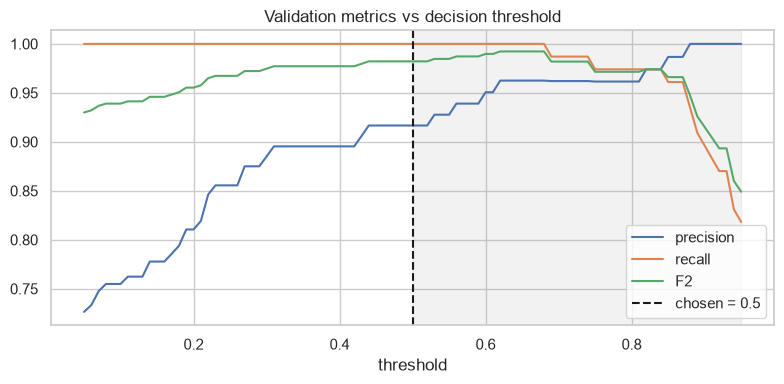

In [25]:
from sklearn.metrics import precision_score, recall_score, fbeta_score
ts = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame({
    "threshold": ts,
    "precision": [precision_score(y_val, p_val >= t, zero_division=0) for t in ts],
    "recall": [recall_score(y_val, p_val >= t) for t in ts],
    "F2": [fbeta_score(y_val, p_val >= t, beta=2) for t in ts],
})
ax = curve.plot(x="threshold", y=["precision", "recall", "F2"], figsize=(8, 4), title="Validation metrics vs decision threshold")
ax.axvline(THRESHOLD, c="k", ls="--", label=f"chosen = {THRESHOLD}"); ax.axvspan(0.5, 0.95, color="grey", alpha=0.1)
ax.legend(); plt.tight_layout(); plt.savefig(FIGS / "threshold.png", dpi=110); plt.show()

**Observations:** on validation, recall is already 1.0 at the default 0.5, and F2 is maximal there, so the threshold stays at **0.5**. The validation and test results are close (test ROC-AUC 0.97, recall 0.97), so the model generalises to unseen patients.

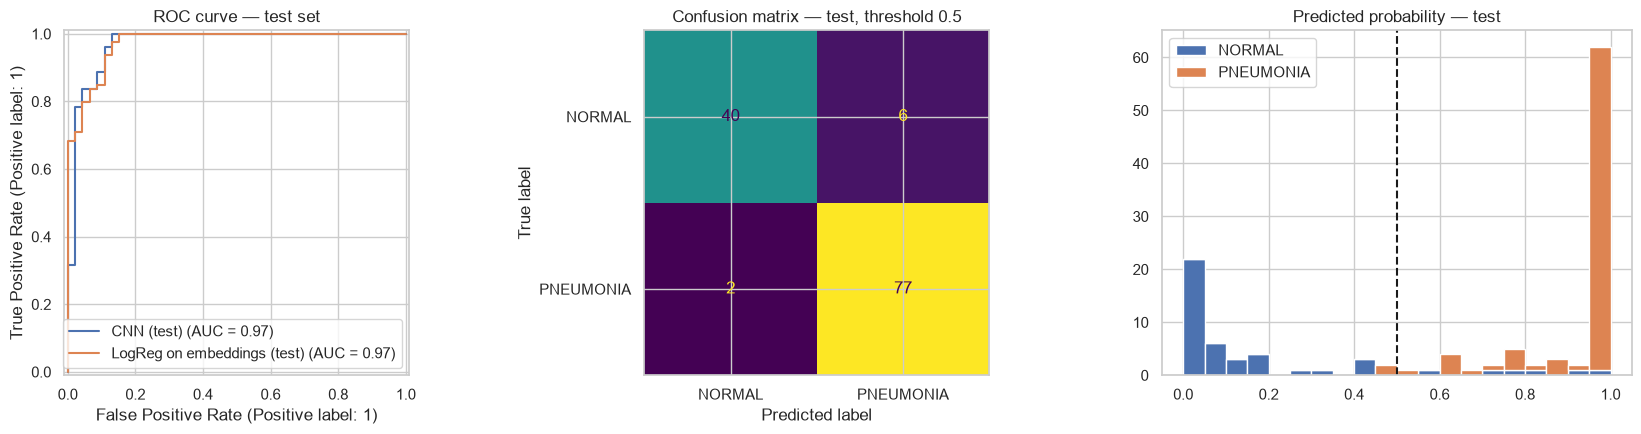

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0], name="CNN (test)")
best_lr_emb = make_pipeline(StandardScaler(), LogisticRegression(C=float(best_baselines.query("features=='embeddings' and model=='logistic_regression'").params.iloc[0].split("=")[1]), max_iter=5000))
best_lr_emb.fit(X["embeddings"]["train"], y["train"])
RocCurveDisplay.from_predictions(y_test, best_lr_emb.predict_proba(X["embeddings"]["test"])[:, 1], ax=axes[0], name="LogReg on embeddings (test)")
axes[0].set_title("ROC curve — test set")
ConfusionMatrixDisplay(confusion_matrix(y_test, p_test >= THRESHOLD), display_labels=common.CLASS_NAMES).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f"Confusion matrix — test, threshold {THRESHOLD}")
axes[2].hist([p_test[y_test == 0], p_test[y_test == 1]], bins=20, label=common.CLASS_NAMES, stacked=True)
axes[2].axvline(THRESHOLD, c="k", ls="--"); axes[2].set_title("Predicted probability — test"); axes[2].legend()
plt.tight_layout(); plt.savefig(FIGS / "final_evaluation.png", dpi=110); plt.show()

**Observations:** on the 125 unseen test images the CNN misses only 2 of 79 pneumonia cases (recall 0.97), and 6 of 46 normal X-rays are false alarms. This trade-off is right for a triage tool. On the test set the CNN's ROC-AUC (0.97) is about the same as the strong *embeddings + logistic regression* baseline, while it was better on validation. With this little data both are good, and the CNN's advantage is modest. The CNN is kept because it won on validation (the pre-registered selection rule) and it produces a single self-contained model for deployment.

### Error analysis by subtype

          accuracy  count
subtype                  
bacteria     1.000     49
normal       0.870     46
virus        0.933     30


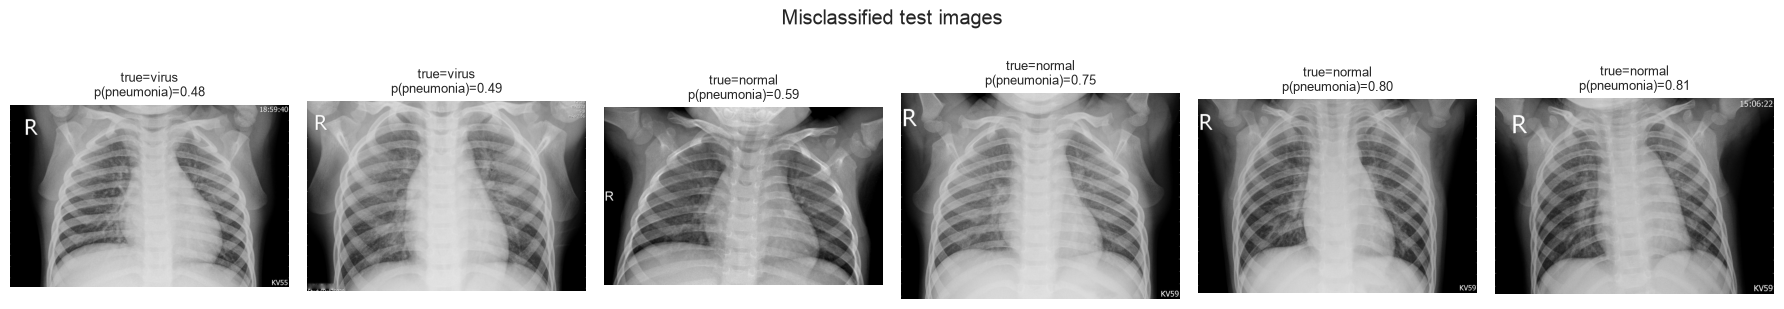

In [27]:
test_df["prob"] = p_test
test_df["pred"] = (p_test >= THRESHOLD).astype(int)
test_df["correct"] = test_df.pred == test_df.label
print(test_df.groupby("subtype").correct.agg(["mean", "count"]).rename(columns={"mean": "accuracy"}).round(3))

errors = test_df[~test_df.correct].sort_values("prob")
fig, axes = plt.subplots(1, min(6, len(errors)), figsize=(18, 3.5), squeeze=False)
for ax, (_, r) in zip(axes[0], errors.head(6).iterrows()):
    ax.imshow(Image.open(r.path), cmap="gray"); ax.axis("off")
    ax.set_title(f"true={r.subtype}\np(pneumonia)={r.prob:.2f}", fontsize=9)
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.savefig(FIGS / "errors.png", dpi=110); plt.show()

**Observations:** bacterial pneumonia is recognised perfectly. Most errors are **false alarms on normal images** (87 % correct) and a few **viral pneumonias** (93 % correct). Viral pneumonia typically produces subtler, more diffuse interstitial patterns than the lobar consolidation of bacterial pneumonia, so this matches clinical intuition.

### Grad-CAM: what is the model looking at?

Grad-CAM highlights the image regions that most increase the pneumonia logit. A sensible model should focus on the lung fields, not on text markers, borders or the edge of the image.

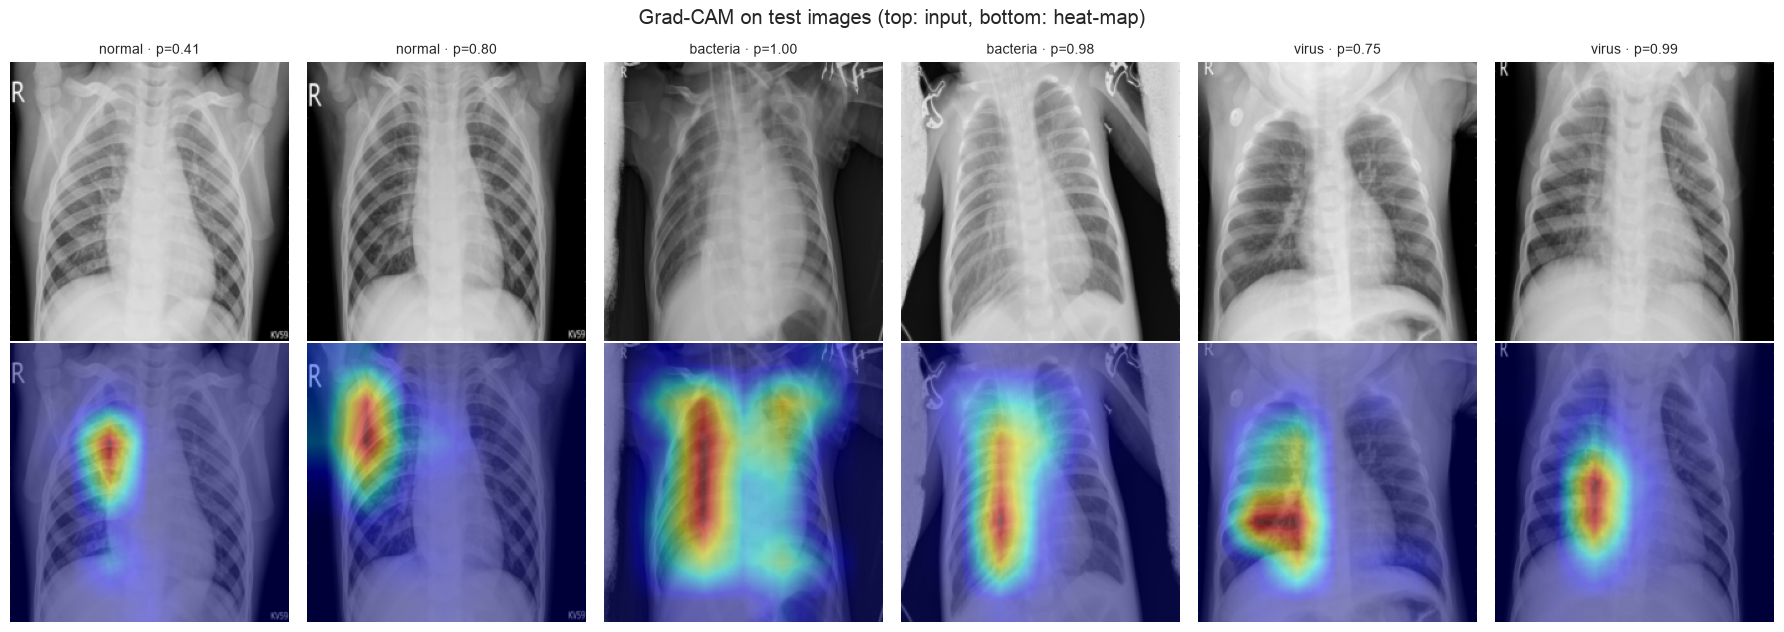

In [28]:
def grad_cam(model, x):
    model = model.cpu().eval()
    target = model.features[0][-1] if isinstance(model.features, torch.nn.Sequential) else model.features.layer4
    acts, grads = {}, {}
    def fwd_hook(m, i, o):
        acts["a"] = o
        o.register_hook(lambda g: grads.__setitem__("g", g))
    h = target.register_forward_hook(fwd_hook)
    logit = model(x)
    model.zero_grad(); logit.sum().backward()
    h.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * acts["a"]).sum(1)).squeeze().detach().numpy()
    cam = np.asarray(Image.fromarray(cam).resize((common.IMG_SIZE, common.IMG_SIZE), Image.BILINEAR))
    return cam / (cam.max() + 1e-8), torch.sigmoid(logit).item()

tf = common.get_transforms(train=False)
examples = pd.concat([test_df[test_df.subtype == s].sample(2, random_state=0) for s in ["normal", "bacteria", "virus"]])
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for i, (_, r) in enumerate(examples.iterrows()):
    img = common.load_resized(r.path)
    cam, p = grad_cam(model, tf(img).unsqueeze(0))
    axes[0, i].imshow(img, cmap="gray"); axes[0, i].axis("off")
    axes[0, i].set_title(f"{r.subtype} · p={p:.2f}", fontsize=10)
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].imshow(cam, cmap="jet", alpha=0.45); axes[1, i].axis("off")
plt.suptitle("Grad-CAM on test images (top: input, bottom: heat-map)")
plt.tight_layout(); plt.savefig(FIGS / "gradcam.png", dpi=110); plt.show()
model = model.to(DEVICE)

**Observations:** the heat-maps are concentrated on the **lung fields and the perihilar region next to the heart**, where pneumonia opacities appear. They are not on the "R" marker, text labels or image borders. This is reassuring given the size shortcut found in the EDA: the model looks at anatomy. It is still not proof that no acquisition artefacts are used (see the README limitations).

## 7. Next step

The selected configuration is hard-coded as the default in `train.py`, which retrains it, evaluates on the test set, and exports the model to **ONNX** (`models/pneumonia_classifier.onnx`) together with `models/metadata.json` (preprocessing constants and the decision threshold). `predict.py` serves the ONNX model with FastAPI + onnxruntime — no PyTorch needed at inference time.